In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import sph_harm_y

In [2]:
#parameters

np.random.seed(7)

#mean CMB temperature in Kelvin
T0 = 2.7255
#rms fluctuations in microkelvin
RMS_uK = 100
#max multiple moment
lmax = 35

n_theta = 181
n_phi = 360

In [3]:
#spherical coords

theta = np.linspace(0.001, np.pi - 0.001, n_theta)
phi = np.linspace(-np.pi, np.pi, endpoint=False)

PHI, THETA = np.meshgrid(phi, theta)

In [4]:
#cmb temperature field

cmb = np.zeros(THETA.shape, dtype=complex)

for l in range(2,lmax+1):
    Cl = 1 / (l * (l + 1)) * np.exp(-(l / 55)**2)
    # m = 0 mode
    a_l0 = np.random.normal() * np.sqrt(Cl)

    cmb += a_l0 * sph_harm_y(l, 0, THETA, phi)

    #positive and negative m modes

    for m in range(1, l + 1):
        a_lm = np.sqrt(Cl / 2) * (np.random.normal() + 1j * np.random.normal())
        Y_pos = sph_harm_y(l, m, THETA, PHI)
        Y_neg = sph_harm_y(l, -m, THETA, PHI)

        cmb += a_lm * Y_pos + (-1)**m * np.conjugate(a_lm) * Y_neg

In [5]:
#temperature fluctuations

delta_T = np.real(cmb)

#remove mean
delta_T -= np.mean(delta_T)

#normalize rms
delta_T_uK = delta_T / np.std(delta_T) * RMS_uK

#convert microkelvin to kelvin
delta_T_K = delta_T_uK * 1e-6

#actual temperature field
temperature = T0 + delta_T_K

In [8]:
#temperature fluctuation map in microKelvin

T_map = delta_T_uK

#multipole array
ls = np.arange(2, lmax + 1)

#storage for angular power spectrum
Cl = np.zeros(len(ls))

#angular grid spacing
dphi = phi[1] - phi[0]

In [9]:
#spherical harmonic decomposition

for i, l in enumerate(ls):
    alm_power = 0.0
    for m in range(-l, l + 1):
        #calculate spherical harmonic
        Ylm = sph_harm_y(l, m, THETA, PHI)

        #integrate temperature map against complex conjugate of spherical harmonic
        integrand = T_map * np.conjugate(Ylm)

        #integrate over azimuthal angle
        phi_integral = np.sum(integrand, axis=1) * dphi * np.sin(theta)

        #integrate over polar angle
        alm = np.trapezoid(phi_integral, x=theta)

        #accumulate harmonic power
        alm_power += np.abs(alm)**2

    #angular power spectrum
    Cl[i] = alm_power / (2 * l + 1)

In [10]:
#calculate D_l

Dl = ls * (ls + 1) / (2 * np.pi) * Cl

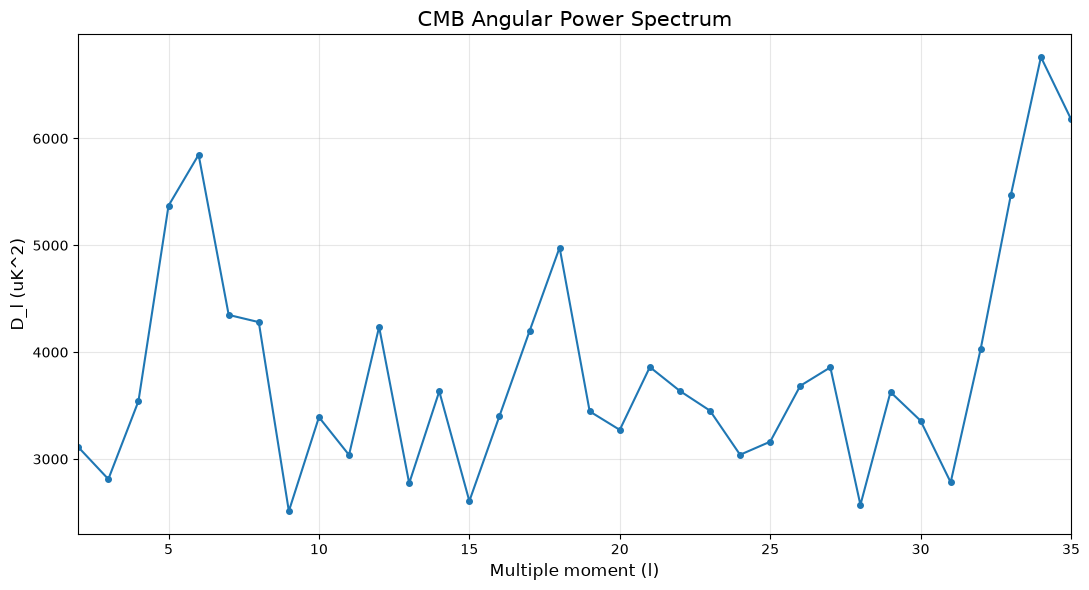

In [11]:
#plot angular power spectrum

plt.figure(figsize=(11, 6))

plt.plot(ls, Dl, marker='o', markersize=4, linewidth=1.5)

plt.xlabel("Multiple moment (l)", fontsize=12)
plt.ylabel("D_l (uK^2)", fontsize=12)
plt.title("CMB Angular Power Spectrum", fontsize=15)

plt.grid(True, alpha=0.3)

plt.xlim(2, lmax)
plt.tight_layout()
plt.show()